In [1]:
import ast
import json
import numpy as np
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

plt.rcParams["font.family"] = "Arial"

from additives_microbiota.plotting import (
    process_string,
    process_string_pretty_vars,
    ecode_category_colors,
    get_ecode_category,
)

In [2]:
path_to_additive_name_mapping = "../data/additive_name_mapping_v3.csv"

## 1. Load Data

### 1.1 Load Open Food Facts Data

In [3]:
off_df = pd.read_pickle("../data/df_food_openfoodfacts_merged.pkl")

print("off_df.shape: ", off_df.shape)
print("columns: ", off_df.columns)

off_df["additives_tags"] = off_df["additives_tags"].apply(
    lambda x: (
        ast.literal_eval(x) if isinstance(x, str) else x if isinstance(x, list) else []
    )
)

off_df_all_additives = []
for i in off_df["additives_tags"]:
    for j in i:
        off_df_all_additives.append(j.replace("en:", ""))

off_df_unique_additives = set(off_df_all_additives)

off_df.shape:  (12710, 46)
columns:  Index(['product_name', 'generic_name', 'quantity', 'brands', 'brands_tags',
       'countries', 'stores', 'categories', 'food_groups', 'ingredients_text',
       'ingredients_tags', 'additives_tags', 'additives_n', 'nova_group',
       'nutriscore_grade', 'ecoscore_grade', 'ecoscore_score', 'labels',
       'allergens', 'traces', 'vegetarian', 'vegan', 'image_url',
       'image_front_url', 'image_ingredients_url', 'image_nutrition_url',
       'barcode', 'error', 'status', 'timestamp', 'has_nutriscore',
       'has_ecoscore', 'has_nova', 'additives_count', 'energy-kcal_100g',
       'proteins_100g', 'carbohydrates_100g', 'sugars_100g', 'fat_100g',
       'saturated-fat_100g', 'fiber_100g', 'salt_100g', 'sodium_100g',
       'calcium_100g', 'iron_100g', 'nutrition-score-fr_100g'],
      dtype='object')


### 1.2 MFR Data Load

In [4]:
df_food = pd.read_pickle("../data/df_food_filtered.pkl")

df_food = df_food.merge(off_df[["barcode", "additives_tags"]], on="barcode", how="left")

# df_food = df_food[~(df_food["eaten_quantity_in_gram"] < 0)]
df_food = df_food[(df_food["eaten_quantity_in_gram"] >= 0)]

df_food["additives_tags"] = df_food["additives_tags"].apply(
    lambda x: (
        ast.literal_eval(x) if isinstance(x, str) else x if isinstance(x, list) else []
    )
)

print(df_food.shape)

(399319, 95)


In [5]:
total_dishes = df_food["dish_id"].nunique()
barcoded_dishes = df_food[(df_food["barcode"].notna())]["dish_id"].nunique()
print(
    total_dishes,
    barcoded_dishes,
)
print(f"Percentage of barcoded dishes: {barcoded_dishes / total_dishes * 100:.2f}%")

233500 42289
Percentage of barcoded dishes: 18.11%


In [6]:
print(
    "Unique barcoded foods containing additives consumed in FAY Cohort: ",
    df_food[
        (df_food["barcode"].notna())
        & (df_food["additives_tags"].apply(lambda x: len(x) > 0))
    ]["barcode"].nunique(),
)
print(
    "Unique barcoded foods consumed in the FAY Cohort: ",
    df_food[(df_food["barcode"].notna())]["barcode"].nunique(),
)

print(
    "Occurrences of barcoded foods containing additives in FAY: ",
    df_food[
        (df_food["barcode"].notna())
        & (df_food["additives_tags"].apply(lambda x: len(x) > 0))
    ].shape,
)
print(
    "Occurrences of barcoded foods in FAY: ",
    df_food[(df_food["barcode"].notna())].shape,
)

Unique barcoded foods containing additives consumed in FAY Cohort:  4119
Unique barcoded foods consumed in the FAY Cohort:  12110
Occurrences of barcoded foods containing additives in FAY:  (16324, 95)
Occurrences of barcoded foods in FAY:  (43251, 95)


In [7]:
print(f"Number of unique subjects: {df_food['subject_key'].nunique()}")

print(
    f"Number of tracking days in the dataset: {df_food.groupby("subject_key")["eaten_date"].nunique().sum()}"
)

Number of unique subjects: 1009
Number of tracking days in the dataset: 14986


In [8]:
df_food.groupby("subject_key")["eaten_date"].nunique().sum()

np.int64(14986)

In [9]:
mfr_additives = []

for i in df_food[df_food["additives_tags"].apply(lambda x: len(x) > 0)][
    "additives_tags"
].values:
    for j in i:
        mfr_additives.append(j.replace("en:", ""))


print(len(mfr_additives), len(set(mfr_additives)))

50841 258


In [10]:
df_food[
    (df_food["barcode"].notna())
    & (df_food["additives_tags"].apply(lambda x: len(x) > 0))
]["food_group_cname"].value_counts()

food_group_cname
sweets_salty_snacks_alcohol           6032
unclassified                          5924
dairy_products_meat_fish_eggs_tofu    1710
grains_potatoes_pulses                1381
vegetables_fruits                      934
non_alcoholic_beverages                295
oils_fats_nuts                          48
Name: count, dtype: int64

In [11]:
df_food[
    (df_food["barcode"].notna())
    & (df_food["additives_tags"].apply(lambda x: len(x) > 0))
    & (df_food["food_group_cname"] == "unclassified")
]["combined_name"].value_counts()

combined_name
unknown                                    470
Saitaku Teriyaki Sauce                      57
Migros - Sirop Hugo (Zero)                  44
alpro - Hafer                               43
Tortilla Wraps, Vollkorn                    34
                                          ... 
Mini Babybel Goat  x6                        1
torino Milk                                  1
ORGANIC MIGROS Purea di mela Applesauce      1
Generoso                                     1
alpro - Joghurt (Heidelbeere)                1
Name: count, Length: 1960, dtype: int64

### 1.3 Save unique barcodes of foods containing additives for Barcode API Section for food group assignment

In [12]:
# Get unique barcodes of foods containing additives
unique_additive_foods = df_food[
    (df_food["barcode"].notna())
    & (df_food["additives_tags"].apply(lambda x: len(x) > 0))
]["barcode"].unique()

unique_additive_foods = sorted(unique_additive_foods)

# Convert to DataFrame and save to CSV with barcode as string
pd.DataFrame(unique_additive_foods, columns=["barcode"]).astype(
    {"barcode": str}
).to_csv("../data/unique_barcodes_with_additives.csv", index=False)

print(len(unique_additive_foods))
# Return the unique barcodes for display in notebook

4119


## 2. One-hot encoding to get the count of each additive across all logged foods

In [13]:
df_food["additive_codes"] = df_food["additives_tags"].apply(
    lambda tags: [t.split(":", 1)[1] for t in tags]
)

# 2) explode and get dummies, then reindex to fill missing rows with 0
temp = df_food["additive_codes"].explode().to_frame("code")
dummies = pd.get_dummies(temp["code"])
dummies = dummies.groupby(level=0).max().reindex(df_food.index, fill_value=0)

# 3) join the one‑hot columns back on and drop the helper
df_food = df_food.join(dummies)
df_food.drop(columns="additive_codes", inplace=True)

In [14]:
df_food.to_pickle("../data/df_food_additives_one_hot.pkl")

## 3. Calculate Daily Additive Intake

In [15]:
unique_additives = list(set(mfr_additives))
unique_additives = [i for i in unique_additives if i != "de:gärungskohlensäure"]

In [16]:
df_food["total_additive_intake"] = df_food[unique_additives].sum(axis=1)

In [17]:
daily_additive_intake = (
    df_food.groupby(["subject_key", "eaten_date"])[
        unique_additives + ["total_additive_intake"]
    ]
    .sum()
    .groupby("subject_key")
    .mean()
    .reset_index()
)

In [18]:
## Option1 : Remove additives based on user prevalence (i.e., non-zero values)

# Calculate the number of non-zero values for each additive column
non_zero_counts = (daily_additive_intake[unique_additives] > 0).sum()

print(non_zero_counts.describe())

low_intake_additives = non_zero_counts[
    non_zero_counts < 0
].index  # Just placeholder for now


## Option2 : Remove additives based on summed intake across users

# summed_daily_additive_intake_across_users = daily_additive_intake.sum(
#     numeric_only=True, axis=0
# ).sort_values(ascending=False)

# print("shape: ", summed_daily_additive_intake_across_users.shape)
# print("Summary: ", summed_daily_additive_intake_across_users.describe())

# low_intake_additives = summed_daily_additive_intake_across_users[
#     summed_daily_additive_intake_across_users < 20
# ].index

# print("Number of low intake additives: ", len(low_intake_additives))

count    257.000000
mean      72.035019
std      125.682460
min        1.000000
25%        5.000000
50%       24.000000
75%       69.000000
max      777.000000
dtype: float64


In [19]:
daily_additive_intake[
    ["subject_key", "total_additive_intake"]
    + [i for i in unique_additives if i not in low_intake_additives]
].to_csv(
    "../data/additive_analysis_files/avg_daily_additive_intake_across_users.csv",
    index=False,
)

In [20]:
daily_additive_intake.set_index("subject_key").sum().sort_values(ascending=False)[:15]

total_additive_intake    3416.881786
e322                      251.868528
e330                      251.270443
e322i                     180.728458
e500                      171.915542
e950                      112.556145
e290                       99.297213
e471                       85.875717
e951                       78.451205
e300                       74.295254
e331                       71.088653
e415                       67.044242
e14xx                      63.646633
e202                       62.732815
e500ii                     62.627934
dtype: float64

In [21]:
daily_additive_intake.describe().T.sort_values("mean", ascending=False)

,count,mean,std,min,25%,50%,75%,max
total_additive_intake,1009.0,3.386404,3.862351,0.0,1.214286,2.357143,4.230769,36.428571
e322,1009.0,0.249622,0.334044,0.0,0.000000,0.142857,0.357143,3.500000
e330,1009.0,0.249029,0.352170,0.0,0.071429,0.142857,0.357143,5.214286
e322i,1009.0,0.179116,0.259366,0.0,0.000000,0.071429,0.250000,2.555556
e500,1009.0,0.170382,0.245105,0.0,0.000000,0.071429,0.222222,2.500000
...,...,...,...,...,...,...,...,...
e251,1009.0,0.000066,0.002099,0.0,0.000000,0.000000,0.000000,0.066667
e155,1009.0,0.000035,0.001124,0.0,0.000000,0.000000,0.000000,0.035714
e948,1009.0,0.000035,0.001124,0.0,0.000000,0.000000,0.000000,0.035714
e580,1009.0,0.000035,0.001124,0.0,0.000000,0.000000,0.000000,0.035714


## 4. Prevalence of intake of additives (by E-code and by Category) across users

### 4.1 Ecode Category Mapping Functions

In [22]:
# DONT DELETE THIS (old version backup)

# def get_ecode_category(code):
#     code = code.lower().strip()

#     # Special cases for specific additives
#     special_cases = {
#         "e14xx": "thickeners_stabilizers_emulsifiers_gelling_agents",
#         "potassium-iodide": "other_additives",
#         # Polydextrose (bulking agent, similar to thickeners)
#         "e1200": "thickeners_stabilizers_emulsifiers_gelling_agents",
#         # Preservatives
#         "e1105": "preservatives_antioxidants",
#         # Processing aids (leavening/flour treatment)
#         # "e919": "ph_regulators_anti_caking_leavening_agents",
#         # "e920": "ph_regulators_anti_caking_leavening_agents",
#     }

#     # Check if the code is in our special cases
#     if code in special_cases:
#         return special_cases[code]

#     # Extract the number and process by range
#     m = re.match(r"^e(\d+)", code)
#     if not m:
#         return "Unknown"

#     num = int(m.group(1))

#     # Main category assignments by number ranges
#     if 200 <= num <= 399:
#         return "preservatives_antioxidants"
#     elif 100 <= num <= 199:
#         return "colorants"
#     elif 400 <= num <= 499:
#         return "thickeners_stabilizers_emulsifiers_gelling_agents"
#     elif 500 <= num <= 599:
#         return "ph_regulators_anti_caking_leavening_agents"
#     elif 600 <= num <= 699:
#         return "flavor_enhancers"
#     elif 700 <= num <= 899:
#         return "other_additives"
#     elif (950 <= num <= 969) or (900 <= num <= 910):
#         return "sweeteners_glazing_agents"
#     # Modified starches (E1400 series) - function as thickeners
#     elif 1400 <= num <= 1499:
#         return "thickeners_stabilizers_emulsifiers_gelling_agents"
#     # All other additives
#     elif 910 <= num <= 1999:
#         return "other_additives"
#     else:
#         return "Unknown"


# ecode_category_colors = {
#     "colorants": "gold",
#     "preservatives_antioxidants": "#66b3ff",
#     "thickeners_stabilizers_emulsifiers_gelling_agents": "#ffcc99",
#     "ph_regulators_anti_caking_leavening_agents": "#b3de69",
#     "flavor_enhancers": "#ffb3e6",
#     "sweeteners_glazing_agents": "#c2c2f0",
#     "other_additives": "#c2f0c2",
#     "unknown": "#cccccc",
# }

### 4.2 Calculating prevalence of additives across users and Assigning Categories

In [23]:
additive_user_prevalence = {}
for col in daily_additive_intake.columns:
    if col in ["subject_key", "total_additive_intake"]:
        continue
    additive_user_prevalence[col] = daily_additive_intake[
        daily_additive_intake[col] > 0
    ].shape[0]

additive_user_prevalence_df = (
    pd.DataFrame(
        additive_user_prevalence.items(), columns=["additive", "prevalence_counts"]
    )
    .set_index("additive")
    .sort_values("prevalence_counts", ascending=False)
)

additive_user_prevalence_df["prevalence"] = (
    additive_user_prevalence_df["prevalence_counts"]
    / daily_additive_intake["subject_key"].nunique()
).round(2)

additive_user_prevalence_df["category"] = additive_user_prevalence_df.index.map(
    lambda x: get_ecode_category(x)
)

additive_user_prevalence_df.to_csv(
    "../data/additive_analysis_files/additive_prevalence_across_users.csv"
)

additive_user_prevalence_df[:50]

,prevalence_counts,prevalence,category
additive,,,
e330,777,0.77,ph_regulators_anti_caking_leavening_agents
e322,742,0.74,thickeners_stabilizers_emulsifiers_gelling_agents
e322i,654,0.65,thickeners_stabilizers_emulsifiers_gelling_agents
e500,640,0.63,ph_regulators_anti_caking_leavening_agents
e471,516,0.51,thickeners_stabilizers_emulsifiers_gelling_agents
e14xx,430,0.43,thickeners_stabilizers_emulsifiers_gelling_agents
e300,428,0.42,preservatives_antioxidants
e415,425,0.42,thickeners_stabilizers_emulsifiers_gelling_agents
e450,407,0.40,ph_regulators_anti_caking_leavening_agents


In [24]:
additive_user_prevalence_df[additive_user_prevalence_df["category"] == "unknown"].index

Index([], dtype='object', name='additive')

In [25]:
additive_user_prevalence_df[
    additive_user_prevalence_df["category"] == "other_additives"
]

,prevalence_counts,prevalence,category
additive,,,
e1100,47,0.05,other_additives
e1510,43,0.04,other_additives
e942,37,0.04,other_additives
e579,20,0.02,other_additives
e941,14,0.01,other_additives
e920,11,0.01,other_additives
e919,8,0.01,other_additives
potassium-iodide,3,0.00,other_additives
e585,1,0.00,other_additives


In [26]:
# Generate a summary of the additive categories
(
    additive_user_prevalence_df.reset_index()
    .groupby("category")
    .agg(count=("additive", "count"), mean_prevalence=("prevalence", "mean"))
    .sort_values("count", ascending=False)
)

,count,mean_prevalence
category,,
ph_regulators_anti_caking_leavening_agents,80,0.072000
thickeners_stabilizers_emulsifiers_gelling_agents,54,0.103148
colorants,47,0.041489
preservatives_antioxidants,35,0.063143
sweeteners_glazing_agents,25,0.084800
other_additives,10,0.018000
flavor_enhancers,6,0.071667


In [27]:
additive_user_prevalence_df.reset_index().groupby("category").agg(
    count=("additive", "count"),
)

,count
category,
colorants,47
flavor_enhancers,6
other_additives,10
ph_regulators_anti_caking_leavening_agents,80
preservatives_antioxidants,35
sweeteners_glazing_agents,25
thickeners_stabilizers_emulsifiers_gelling_agents,54


### 4.3 Plotting Prevalence of Additives and Saving the plot

In [28]:
def plot_food_additives_by_category(
    df,
    additive_names,
    figsize=(14, 16),
    title=None,
    legend_loc=(0.37, 1),
    show_legend=True,
):
    """
    Group food additives by E-code categories and create a horizontal bar plot.

    Parameters:
    -----------
    df : pandas.DataFrame
        DataFrame with additives as index and a 'prevalence' column
    additive_names : dict, optional
        Dictionary mapping E-codes to their actual names (e.g., {'e330': 'Citric acid'})
    figsize : tuple, optional
        Figure size as (width, height) in inches
    title : str, optional
        Plot title
    legend_loc : tuple, optional
        Location for the legend
    show_legend : bool, optional
        Whether to show the legend or not

    Returns:
    --------
    fig : matplotlib.figure.Figure
        The figure object containing the plot
    df_grouped : pandas.DataFrame
        The processed DataFrame with additives and their categories
    summary : pandas.DataFrame
        Summary DataFrame with counts and total prevalence by category
    """

    # Reset index to have the additive codes as a column
    df_reset = df.reset_index().copy()

    # Ensure column names match expected format
    if "additive" not in df_reset.columns:
        column_name_map = {df_reset.columns[0]: "additive"}
        if len(df_reset.columns) > 1:
            column_name_map[df_reset.columns[1]] = "prevalence"
        df_reset = df_reset.rename(columns=column_name_map)

    # Convert codes to lowercase for consistency
    df_reset["code"] = df_reset["additive"].str.lower()

    # Default E-code to name mapping if not provided
    if additive_names is None:
        # Raise error if additive_names is None
        raise ValueError(
            "additive_names must be provided to map E-codes to their names"
        )

    # Add additive names to the DataFrame
    df_reset["additive_name"] = df_reset["code"].map(additive_names)

    # For codes without a mapping, use the code itself
    df_reset["additive_name"] = df_reset["additive_name"].fillna(df_reset["code"])

    # Sort by category and prevalence within category
    df_grouped = df_reset.sort_values(
        ["category", "prevalence"], ascending=[True, False]
    )

    # Define color palette for categories

    # Set up the figure
    fig, ax = plt.subplots(figsize=figsize)
    # sns.set_style("white")  # No gridlines

    # Create a range for the y-axis
    y_positions = range(len(df_grouped))

    # Create the horizontal bar plot
    bars = ax.barh(
        y=y_positions,
        width=df_grouped["prevalence"],
        color=[
            ecode_category_colors.get(cat, "#cccccc") for cat in df_grouped["category"]
        ],
    )

    # Customize the plot
    ax.set_xlabel(
        "Prevalence (across users)",
    )
    if title is not None:
        ax.set_title(title, fontsize=16)

    # Add y-ticks with additive names
    ax.set_yticks(y_positions)

    # Create labels that include both code and name
    y_labels = [
        f"{row['code']} - {row['additive_name']}" for idx, row in df_grouped.iterrows()
    ]

    # Truncate very long names
    y_labels = [label[:40] + "..." if len(label) > 40 else label for label in y_labels]

    ax.set_yticklabels(y_labels, fontsize=8)

    # Remove grid
    ax.grid(False)

    # Add text labels for prevalence values
    for i, (idx, row) in enumerate(df_grouped.iterrows()):
        ax.text(
            row["prevalence"] + max(df_grouped["prevalence"]) * 0.01,
            i,
            f"{row['prevalence']}",
            va="center",
            fontsize=8,
        )

    # # Track category changes for dividers and labels
    # current_category = None
    # category_positions = {}

    # for i, (idx, row) in enumerate(df_grouped.iterrows()):
    #     if row["category"] != current_category:
    #         current_category = row["category"]
    #         if i > 0:
    #             ax.axhline(
    #                 i - 0.5, color="black", linestyle="-", alpha=0.3, linewidth=0.8
    #             )
    #         category_positions[current_category] = i

    # # Add category labels on the left side
    # for category, pos in category_positions.items():
    #     ax.text(
    #         -max(df_grouped["prevalence"])
    #         * 0.2,  # Adjusted position for better visibility with y-labels
    #         pos,
    #         category,
    #         fontsize=10,
    #         fontweight="bold",
    #         ha="right",
    #         va="center",
    #         bbox=dict(facecolor="white", alpha=0.7, edgecolor="none", pad=2),
    #     )

    # Add a legend for categories that are present in the data
    if show_legend:
        legend_elements = [
            Patch(
                facecolor=color,
                edgecolor="black",
                linewidth=0.5,
                label=process_string(cat, newLineSep=7),
            )
            for cat, color in ecode_category_colors.items()
            if cat in df_grouped["category"].unique()
        ]
        legend = ax.legend(
            handles=legend_elements,
            frameon=False,
            fontsize=9,
            bbox_to_anchor=legend_loc,
        )

    # Adjust layout and margins
    plt.tight_layout()
    plt.subplots_adjust(left=0.3)  # Make more room for the y-axis labels
    plt.margins(y=0.01)

    # Set x-axis limit to 0-1000 as requested
    ax.set_xlim(0, 1)

    return fig, df_grouped

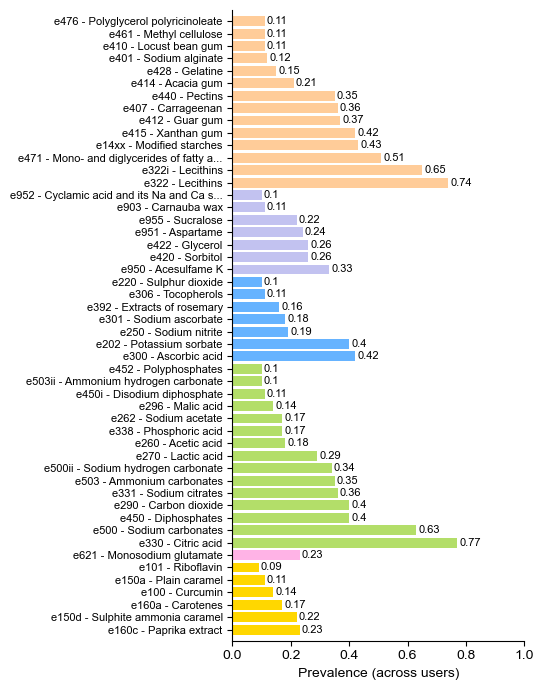

In [29]:
# Usage (showing top 50 additives):
prevalence_plot_df = additive_user_prevalence_df[:50]

# Loading additive names
additive_name_mapping = pd.read_csv(path_to_additive_name_mapping)
additive_names = dict(
    zip(additive_name_mapping["ecode"], additive_name_mapping["name"])
)

# Plotting prevalence of additives across users
fig, plot_df_ecode_grouped = plot_food_additives_by_category(
    df=prevalence_plot_df,
    additive_names=additive_names,
    figsize=(4.5, 7),
    title=None,  # "Prevalence of Food Additives (Top 50)",
    legend_loc=(0.47, 0.5),
    show_legend=False,
)
sns.despine()

plt.savefig(
    "../analysis/figures/additive_descriptive/prevalence_of_food_additives_top_50.png",
    dpi=300,
    bbox_inches="tight",
)

In [30]:
plot_df_ecode_grouped.sort_values("prevalence", ascending=False)

,additive,prevalence_counts,prevalence,category,code,additive_name
0,e330,777,0.77,ph_regulators_anti_caking_leavening_agents,e330,Citric acid
1,e322,742,0.74,thickeners_stabilizers_emulsifiers_gelling_agents,e322,Lecithins
2,e322i,654,0.65,thickeners_stabilizers_emulsifiers_gelling_agents,e322i,Lecithins
3,e500,640,0.63,ph_regulators_anti_caking_leavening_agents,e500,Sodium carbonates
4,e471,516,0.51,thickeners_stabilizers_emulsifiers_gelling_agents,e471,Mono- and diglycerides of fatty acids
5,e14xx,430,0.43,thickeners_stabilizers_emulsifiers_gelling_agents,e14xx,Modified starches
7,e415,425,0.42,thickeners_stabilizers_emulsifiers_gelling_agents,e415,Xanthan gum
6,e300,428,0.42,preservatives_antioxidants,e300,Ascorbic acid
8,e450,407,0.40,ph_regulators_anti_caking_leavening_agents,e450,Diphosphates
10,e290,402,0.40,ph_regulators_anti_caking_leavening_agents,e290,Carbon dioxide


### 4.4 Calculate Additive Intake by Category and Saving to CSV file

In [31]:
dai = daily_additive_intake.set_index("subject_key").T
dai.drop(["total_additive_intake"], inplace=True)
dai.index = dai.index.map(get_ecode_category)
# Sum additives by category
dai_grouped = dai.groupby(level=0).sum()
dai_grouped.T.to_csv(
    "../data/additive_analysis_files/avg_daily_additive_intake_across_users_by_category.csv"
)

print(dai.index.value_counts())

ph_regulators_anti_caking_leavening_agents           80
thickeners_stabilizers_emulsifiers_gelling_agents    54
colorants                                            47
preservatives_antioxidants                           35
sweeteners_glazing_agents                            25
other_additives                                      10
flavor_enhancers                                      6
Name: count, dtype: int64


## 5. Barcoded Foods Consumption

In [32]:
all_user_res = pd.DataFrame()
for user in df_food["subject_key"].unique()[:]:
    user_df = df_food[df_food["subject_key"] == user]
    res_barcoded_eaten = {}
    for date in user_df["eaten_date"].unique():
        date_df = user_df[
            (user_df["eaten_date"] == date)
            & (user_df["barcode"].notna())
            & (user_df["additives_tags"].apply(lambda x: len(x) > 0))
        ]
        if len(date_df) == 0:
            res_barcoded_eaten[date] = 0
        else:
            res_barcoded_eaten[date] = date_df["energy_kcal_eaten"].sum()

    user_res = (
        pd.DataFrame([res_barcoded_eaten])
        .T.reset_index()
        .rename(columns={"index": "eaten_date", 0: "additive_food_kcal_eaten"})
    )
    user_res["subject_key"] = user
    all_user_res = pd.concat([all_user_res, user_res])

all_user_res

count    1009.000000
mean       82.776955
std       117.527402
min         0.000000
25%         0.000000
50%        25.625000
75%       133.820000
max       764.625000
Name: additive_food_kcal_eaten, dtype: float64


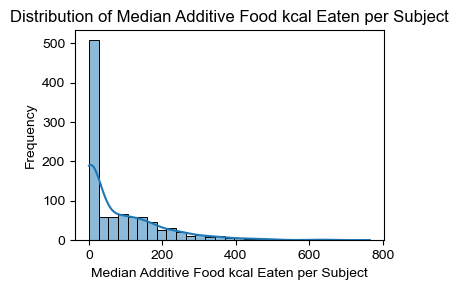

In [33]:
# Calculate median additive food kcal eaten per subject
median_per_subject = all_user_res.groupby("subject_key")[
    "additive_food_kcal_eaten"
].median()

# Create a figure and axis
plt.figure(figsize=(4, 3))

# Plot histogram with KDE
sns.histplot(median_per_subject, kde=True)

# Add labels and title
plt.xlabel("Median Additive Food kcal Eaten per Subject")
plt.ylabel("Frequency")
plt.title("Distribution of Median Additive Food kcal Eaten per Subject")

# Show descriptive statistics
print(median_per_subject.describe())

# Display the plot
plt.tight_layout()
plt.show()

In [34]:
median_per_subject.describe()

count    1009.000000
mean       82.776955
std       117.527402
min         0.000000
25%         0.000000
50%        25.625000
75%       133.820000
max       764.625000
Name: additive_food_kcal_eaten, dtype: float64

In [35]:
all_user_res.to_csv("../data/additive_analysis_files/user_additive_food_kcal_eaten.csv")

# Additive Day Presence Across Users

In [36]:
additive_intake_daywise_df = df_food.groupby(["subject_key", "eaten_date"])[
    unique_additives + ["total_additive_intake"]
].sum()

additive_intake_daywise_df.columns = [
    (cat if cat != "unknown" else col)
    for col in additive_intake_daywise_df.columns
    for cat in [get_ecode_category(col)]
]

additive_intake_daywise_df = additive_intake_daywise_df.T.groupby(level=0).sum().T

In [37]:
additive_day_presence = (
    additive_intake_daywise_df.drop(columns=["total_additive_intake"])
    .gt(0)
    .groupby(level="subject_key")
    .mean()
)

any_additive_prop = (
    additive_intake_daywise_df["total_additive_intake"]
    .gt(0)
    .groupby(level="subject_key")
    .mean()
)

additive_day_presence["any_additive_intake"] = any_additive_prop

additive_day_presence.columns = [
    i + "_days_fraction" for i in additive_day_presence.columns
]
additive_day_presence.to_csv(
    "../data/additive_analysis_files/additive_day_presence_by_subject.csv"
)

## Barcoded Foods Sugar Consumption

In [ ]:
total_days = df_food.groupby("subject_key")["eaten_date"].nunique()
barcoded_sugar = (
    df_food[df_food["barcode"].notna()].groupby("subject_key")["sugar_eaten"].sum()
)

avg_barcoded_sugar_per_day = (
    barcoded_sugar.reindex(total_days.index, fill_value=0) / total_days
)
avg_barcoded_sugar_per_day = avg_barcoded_sugar_per_day.rename(
    "barcoded_foods_sugar_eaten"
)

avg_barcoded_sugar_per_day.to_csv(
    "../data/additive_analysis_files/avg_daily_barcoded_foods_sugar_consumption.csv"
)